# Figure 2: single-star chromospheric density profiles

Run all cells in order to plot the single-star density profiles from
*Enhanced Mass Transfer from Extended Shock-Supported Stellar Chromospheres*.
The three pairs of dimensionless thermal and convective speeds represent the
main sequence, red clump, and red-giant/asymptotic-giant phases of a solar-mass star.
The output is `paper_figures/1msun_density_profile_uoa_seminar.png` relative to
the kernel's working directory.

**Dependencies:** NumPy, pandas, Matplotlib, and the simulation profile
`agb2026_1Msun/st29gm03n003_xc_rho.txt` (radius in cm; density in g cm$^{-3}$).
Set `DATA_DIR` below to the folder containing this profile.


In [14]:
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Run from the project directory, or replace DATA_DIR with your data location.
DATA_DIR = Path('./')
PROFILE_RELATIVE_PATH = Path('agb2026_1Msun/st29gm03n003_xc_rho.txt')

OUTPUT_DIR = Path('./paper_figures')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Set plot fonts and axis styling.
mpl.rcParams.update({
    'text.usetex': False,
    'axes.formatter.use_mathtext': True,
    'font.family': 'STIXGeneral',
    'mathtext.fontset': 'cm',
    'axes.unicode_minus': False,
    'axes.linewidth': 1.5,
})

## Density model and quadrature

Use $x=r/R_{\rm ph}$, $u=v_s/v_{\rm esc}$,
$f_T=c_T/v_{\rm esc}$, and $f_{\rm con}=v_{\rm con}/v_{\rm esc}$.
The shock-speed integral uses 10,000 midpoint samples over
$0<u<x^{-1/2}$, with the upper limit set by the local escape speed.

The density integral has prefactor
$\sqrt{2/\pi}\,\rho_{\rm ph}/f_{\rm con}$.
The thermal profile is
$\rho_{\rm ph}\exp[(x^{-1}-1)/(2f_T^2)]$.


In [9]:
def rho_integral(rho_ph, r_by_Rph, f_T, f_con, N=10000):
    """Average the spherical density over a truncated half-normal shock speed.

    rho_ph supplies the density units; r_by_Rph, f_T, and f_con are dimensionless.
    Set rho_ph=1 to obtain the density normalized to the photosphere.
    """
    Rph_by_r = 1.0 / r_by_Rph
    vmax = np.sqrt(Rph_by_r)  # Local escape speed / photospheric escape speed.
    dv = vmax / N
    v = np.linspace(dv / 2, vmax - dv / 2, N)

    # Potential difference and spherical area factor, then the Gaussian weight.
    term1 = (Rph_by_r - 1 + 4 * v**2 * np.log(Rph_by_r)) / (v**2 + f_T**2)
    term2 = v**2 / f_con**2
    integral = np.sum(np.exp(0.5 * (term1 - term2))) * dv
    return np.sqrt(2 / np.pi) * (rho_ph / f_con) * integral


def thermal_atm(rho_ph, r_by_Rph, f_T):
    """Isothermal hydrostatic density in a spherical gravitational potential."""
    Rph_by_r = 1.0 / r_by_Rph
    return rho_ph * np.exp((Rph_by_r - 1.0) / (2 * f_T**2))

## Evaluate the three stellar examples

Evaluate the profiles on a 100-point radial grid using the thermal and
convective speed parameters below. The figure labels round these values for
readability. Thin solid lines halve only $f_{\rm con}$; dashed lines use
thermal support alone.


In [10]:
r_by_Rph_grid = np.linspace(1, 4, 30000)
f_Ts = [0.012, 0.03, 0.12]
f_cons = [0.0058, 0.02, 0.10287489447199147]

dens_profile = np.zeros((len(f_Ts), len(r_by_Rph_grid)))
dens_profile_halffcon = np.zeros_like(dens_profile)
thermal_dens_profile = np.zeros_like(dens_profile)

for i, (f_T, f_con) in enumerate(zip(f_Ts, f_cons)):
    for j, r_by_Rph in enumerate(r_by_Rph_grid):
        dens_profile[i, j] = rho_integral(1.0, r_by_Rph, f_T, f_con)
        dens_profile_halffcon[i, j] = rho_integral(1.0, r_by_Rph, f_T, f_con / 2.0)
        thermal_dens_profile[i, j] = thermal_atm(1.0, r_by_Rph, f_T)

## Normalize the hydrodynamical comparison

The `st29gm03n003` profile is sampled from the outside inward. Select points at
or below the photospheric-density threshold, use the innermost selected sample
to define $R_{\rm ph}$ and $\rho_{\rm ph}$, and interpolate the normalized
profile at 20 radii. The resulting arrays are available for the optional
simulation overlay in the plotting cell.


In [11]:
phot_dens = 1.325297250047596e-09  # g cm^-3; photospheric-density selection threshold.
simulation = pd.read_csv(DATA_DIR / PROFILE_RELATIVE_PATH, sep=r'\s+', header=None)
simulation = simulation[simulation[1] <= phot_dens]
rphot = simulation[0].values[-1]  # cm
rhophot = simulation[1].values[-1]  # g cm^-3

#plot_grid = np.linspace(1, 3.1, 20)
plot_grid = 1+np.logspace(-2.5, np.log10(3.1), 20)
# np.interp requires increasing radii; reverse this outside-to-inside profile.
rho_grid = np.interp(
    plot_grid,
    simulation[0].values[::-1] / rphot,
    simulation[1].values[::-1] / rhophot,
)

print(plot_grid)

[1.00316228 1.00454402 1.0065295  1.00938254 1.01348219 1.01937316
 1.02783816 1.0400019  1.05748052 1.08259634 1.11868638 1.17054578
 1.24506488 1.3521447  1.5060125  1.72711204 2.04481988 2.5013485
 3.15735495 4.1       ]


## Draw and save Figure 2

Plot the density profiles with rounded parameter annotations and save a
200-dpi PNG. The plotting cell creates a figure with logarithmic density and
linear radius axes. The simulation overlay is disabled; uncomment the
`ax.scatter` line to display it.


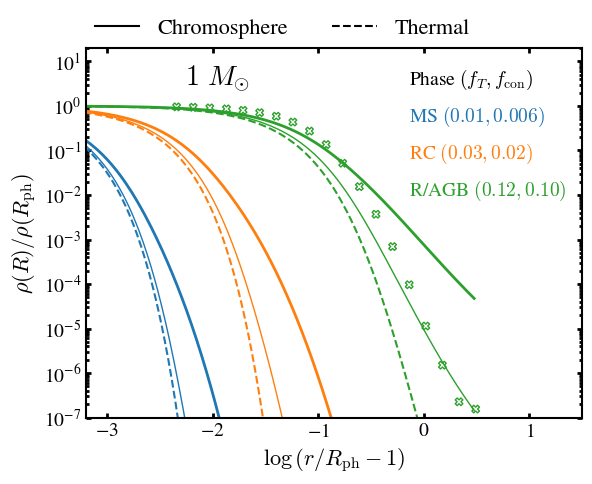

In [12]:
fig, ax = plt.subplots(figsize=(6.4, 4.8))

for i in range(len(f_Ts)):
    color = f'C{i}'
    ax.plot(np.log10(r_by_Rph_grid[1:] - 1), dens_profile[i][1:], color=color, linewidth=2)
    ax.plot(np.log10(r_by_Rph_grid[1:] - 1), dens_profile_halffcon[i][1:], color=color, linewidth=1)
    ax.plot(np.log10(r_by_Rph_grid[1:] - 1), thermal_dens_profile[i][1:], linestyle='--', color=color)

ax.set_yscale('log')
# Legend-only entries lie outside the displayed radial range.
ax.plot(0, 1, color='k', label='Chromosphere')
ax.plot(0, 1, color='k', linestyle='--', label='Thermal')
ax.set_ylabel(r'$\rho(R)/\rho(R_{\rm ph})$', fontsize=16)
ax.set_xlabel(r'$\log\left(r/R_{\rm ph}-1\right)$', fontsize=16)
ax.tick_params(which='both', direction='in', top=True, right=True,
               labelsize=14, labelbottom=True, width=2)

ytext = 0.9
xoffset = 0.05
#ax.text(0.66 + xoffset, ytext, r'$f_T$', transform=ax.transAxes, fontsize=16)
#ax.text(0.81 + xoffset, ytext, r'$f_{\rm con}$', transform=ax.transAxes, fontsize=16)
ax.text(0.6 + xoffset, ytext, r'Phase $(f_T, f_{\rm con})$', transform=ax.transAxes, fontsize=14, color='k')

# Display values are rounded; the computation above uses the full parameter values.
annotations = [('MS', '0.01', '0.006'), ('RC', '0.03', '0.02'), ('R/AGB', '0.12', '0.10')]
for i, (phase, f_T_label, f_con_label) in enumerate(annotations):
    y = ytext - 0.1 * (i + 1)
    #ax.text(0.48 + xoffset, y, phase, transform=ax.transAxes, fontsize=14, color=f'C{i}')
    #ax.text(0.65 + xoffset, y, f'${f_T_label}$', transform=ax.transAxes, fontsize=14, color=f'C{i}')
    #ax.text(0.8 + xoffset, y, f'${f_con_label}$', transform=ax.transAxes, fontsize=14, color=f'C{i}')
    ax.text(0.6 + xoffset, y, f'{phase} $({f_T_label}, {f_con_label})$', transform=ax.transAxes, fontsize=14, color=f'C{i}')

ax.text(0.2, 0.9, r'$1~M_{\odot}$', transform=ax.transAxes, fontsize=20, color='k')
ax.legend(loc=(0, 1), framealpha=0.0, fontsize=16, ncols=2)
#ax.set_ylim(1e-7, 4)
ax.set_ylim(1e-7, 20)
#ax.set_xlim(0.9, 3.1)
ax.set_xlim(-3.2, 1.5)
ax.scatter(np.log10(plot_grid[1:]-1), rho_grid[1:], marker='X', s=30, facecolors='None', edgecolors='C2')

fig.savefig(OUTPUT_DIR / '1msun_density_profile_revised.png', dpi=200, bbox_inches='tight')
plt.show()